In [8]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
np.random.seed(42)

points1 = np.random.randn(50, 2) + [2, 2]
points2 = np.random.randn(50, 2) + [8, 3]
points3 = np.random.randn(50, 2) + [5, 8]

X = np.vstack((points1, points2, points3))

In [10]:
K = 3
random_indices = np.random.choice(len(X), K, replace=False)
centroids = X[random_indices].copy()

history = [centroids.copy()]

In [11]:
max_iterations = 100

for iteration in range(max_iterations):

    distances = np.linalg.norm(
        X[:, np.newaxis] - centroids,
        axis=2
    )

    labels = np.argmin(distances, axis=1)
    distances = np.linalg.norm(
        X[:, np.newaxis] - centroids,
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    new_centroids = np.array([
        X[labels == k].mean(axis=0)
        if np.any(labels == k)
        else centroids[k]
        for k in range(K)
    ])
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids
    history.append(centroids.copy())

In [12]:
print("Number of iterations:", iteration + 1)
print("Final Centroids:")
print(centroids)

Number of iterations: 6
Final Centroids:
[[5.04165929 8.08045085]
 [1.86432437 1.9279826 ]
 [7.87836631 3.25353365]]


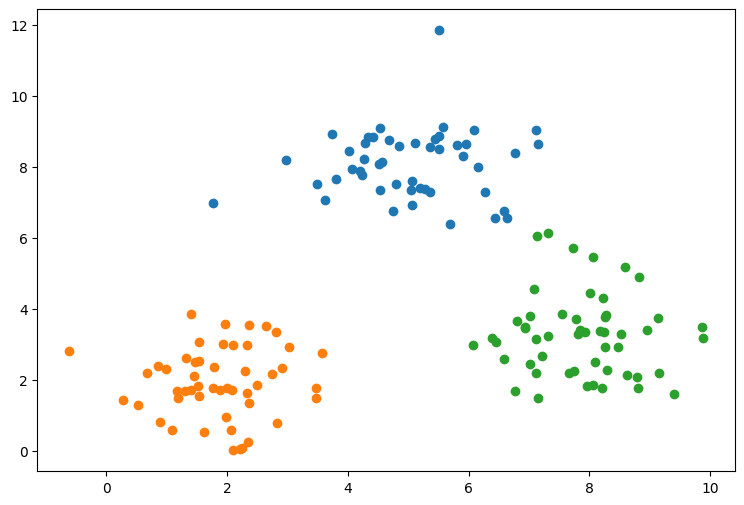

In [13]:
plt.figure(figsize=(9, 6))

for k in range(K):
    plt.scatter(
        X[labels == k, 0],
        X[labels == k, 1],
        label=f'Cluster {k + 1}'
    )

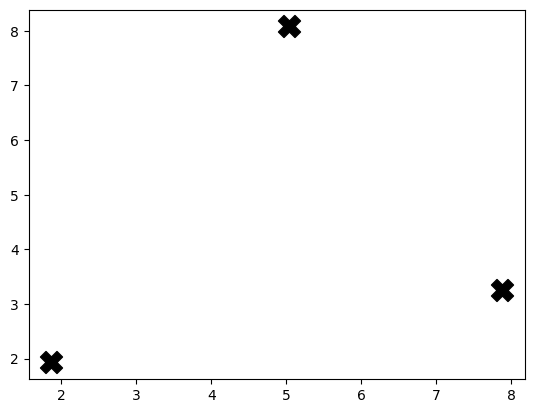

In [14]:
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Centroids'
)